**Project Title:** Customer Transaction Prediction Using Machine Learning

**Project Type:** Supervised Machine Learning, Binary Classification

**Domain:** Finance / Banking

**Contribution:** Individual

Project Objective

Main objective: Build a machine learning model that helps the bank predict which customers will make a transaction in the future, regardless of the amount transacted.

Specific Objectives
1. Understand the data: Analyze the 200 anonymized features and the target variable (data quality, distributions, class imbalance, correlations) and prepare a data analysis report.
2. Handle class imbalance: Address the skewed target (about 90% non-transacting vs 10% transacting) using techniques such as class weights and SMOTE, and evaluate with the right metrics.
3. Build and compare multiple models: Train several classifiers (Logistic Regression, Random Forest, XGBoost, LightGBM) and compare them on ROC-AUC, F1, precision, and recall.
4. Optimize the best model: Improve performance through feature engineering, hyperparameter tuning, cross-validation, and threshold selection.
5. Recommend a production model: Choose the best model considering accuracy, speed, interpretability, and ease of retraining, and justify the choice in a Model Comparison Report.
6. Document challenges: Record the problems faced (imbalance, anonymized features, weak signal, overfitting) and the technique used for each, with reasons, in a Challenges Report.

**Step 1: Setup**

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, classification_report,
                             confusion_matrix, precision_recall_curve, f1_score)
import lightgbm as lgb
import xgboost as xgb
from imblearn.over_sampling import SMOTE

**Step 2: Load data and basic inspection**

In [4]:
df = pd.read_csv("train(1).csv")

In [14]:
df

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77766,train_77766,0,8.5068,-5.7108,14.2916,2.2121,11.0838,-15.7812,5.1060,18.5408,...,4.1601,5.0357,1.0371,0.8043,17.2825,-0.8774,-2.2331,8.9139,24.2769,4.7677
77767,train_77767,0,7.5882,1.7263,14.2025,6.8625,14.0336,-5.0227,4.5952,17.5565,...,1.8988,14.7392,0.7640,3.7807,15.8102,-1.6859,-1.9436,9.3841,18.6804,-10.8824
77768,train_77768,0,7.7918,2.9118,8.9783,8.8808,9.5337,-10.6875,7.1386,19.1204,...,3.1555,7.3619,-0.3538,4.0563,18.0504,-2.5104,7.0536,8.6688,13.2719,-12.8254
77769,train_77769,0,10.2687,-2.4350,17.1282,6.1669,10.5290,-17.0372,4.6286,14.6912,...,6.1415,3.0398,2.1145,6.8823,14.0602,1.8216,5.5481,8.3376,12.8767,-13.9455


In [6]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [10]:
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
77766,train_77766,0,8.5068,-5.7108,14.2916,2.2121,11.0838,-15.7812,5.1060,18.5408,...,4.1601,5.0357,1.0371,0.8043,17.2825,-0.8774,-2.2331,8.9139,24.2769,4.7677
77767,train_77767,0,7.5882,1.7263,14.2025,6.8625,14.0336,-5.0227,4.5952,17.5565,...,1.8988,14.7392,0.7640,3.7807,15.8102,-1.6859,-1.9436,9.3841,18.6804,-10.8824
77768,train_77768,0,7.7918,2.9118,8.9783,8.8808,9.5337,-10.6875,7.1386,19.1204,...,3.1555,7.3619,-0.3538,4.0563,18.0504,-2.5104,7.0536,8.6688,13.2719,-12.8254
77769,train_77769,0,10.2687,-2.4350,17.1282,6.1669,10.5290,-17.0372,4.6286,14.6912,...,6.1415,3.0398,2.1145,6.8823,14.0602,1.8216,5.5481,8.3376,12.8767,-13.9455
77770,train_77770,0,9.6723,-0.2632,10.4098,7.2146,11.9891,-3.5120,4.9607,19.1196,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
df.sample(4)

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
63988,train_63988,0,7.4799,-2.3228,9.6858,7.1851,10.2202,4.5331,5.1952,16.0990,...,0.8114,6.5678,4.4666,2.3694,22.7623,-0.1886,-1.1340,7.8675,11.3626,5.2509
72326,train_72326,0,6.7535,-3.0331,12.8778,2.2571,10.1646,-2.8198,4.2006,15.5849,...,5.5104,8.7001,-0.4442,3.8110,14.7747,-2.8272,-4.2294,10.0768,13.5608,12.4344
33090,train_33090,0,6.2363,-4.8640,6.4903,4.6441,11.0337,4.5730,5.4561,21.8350,...,8.0582,11.1613,3.0980,4.9721,14.8840,-1.3718,8.6269,9.8863,16.2521,4.3031
8162,train_8162,0,9.4228,-5.3154,12.2504,7.9343,8.7879,-10.1275,3.7974,21.0164,...,2.8776,5.6576,0.8457,0.6078,20.4030,-1.0691,-2.5636,8.1414,13.2323,1.8167


In [8]:
df.shape

(77771, 202)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77771 entries, 0 to 77770
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 119.9+ MB


In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
target,77771.0,0.100320,0.300428,0.0000,0.000000,0.00000,0.000000,1.0000
var_0,77771.0,10.674760,3.043653,0.5979,8.450550,10.52500,12.754650,20.3150
var_1,77771.0,-1.650308,4.049204,-14.0325,-4.756450,-1.63410,1.338750,10.3356
var_2,77771.0,10.699343,2.633905,2.7892,8.716750,10.56240,12.494200,18.6521
var_3,77771.0,6.794868,2.045490,-0.0402,5.252200,6.82560,8.329400,12.9773
...,...,...,...,...,...,...,...,...
var_195,77770.0,-0.139479,1.429400,-5.0481,-1.164000,-0.17240,0.828300,4.2729
var_196,77770.0,2.296033,5.461489,-14.0204,-1.978100,2.39990,6.543525,18.3215
var_197,77770.0,8.910548,0.919969,5.9606,8.256200,8.89070,9.592700,12.0004
var_198,77770.0,15.875039,3.012086,6.2993,13.842275,15.93670,18.063675,26.0346


In [12]:
df.isnull().sum()

,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
...,...
var_195,1
var_196,1
var_197,1
var_198,1


**Step 3: Data quality checks (Task 1: Analysis Report)**

Missing: 80
Duplicates: 0
Duplicate IDs: 0
target
0    0.89968
1    0.10032
Name: proportion, dtype: float64


<Axes: xlabel='target', ylabel='count'>

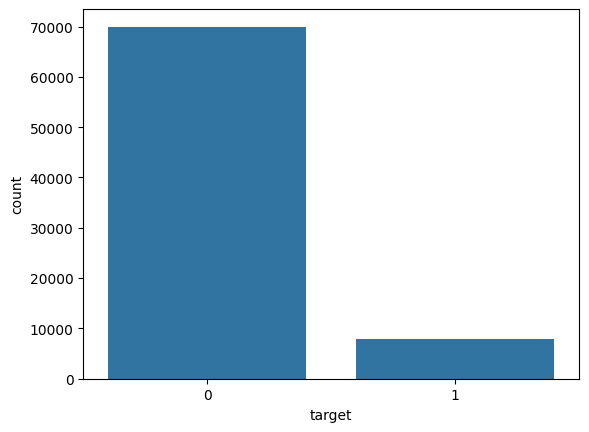

In [13]:
print("Missing:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Duplicate IDs:", df['ID_code'].duplicated().sum())

print(df['target'].value_counts(normalize=True))
sns.countplot(x='target', data=df)

**Step 4: Light EDA**

var_44   -0.350276
var_93   -0.235862
var_81   -0.234079
var_80   -0.221845
var_86   -0.220108
dtype: float64 var_0      0.233036
var_163    0.233079
var_179    0.245480
var_168    0.267305
var_2      0.268117
dtype: float64
var_81    -0.078242
var_139   -0.074308
var_12    -0.071222
var_146   -0.062683
var_174   -0.059888
var_166   -0.059088
var_80    -0.057978
var_21    -0.057746
var_76    -0.057418
var_165   -0.055436
Name: target, dtype: float64
var_2      0.051136
var_179    0.052241
var_170    0.053057
var_99     0.056822
var_190    0.057088
var_22     0.057682
var_53     0.060087
var_110    0.064012
var_6      0.064366
var_26     0.066233
Name: target, dtype: float64


<Axes: title={'center': 'var_5'}>

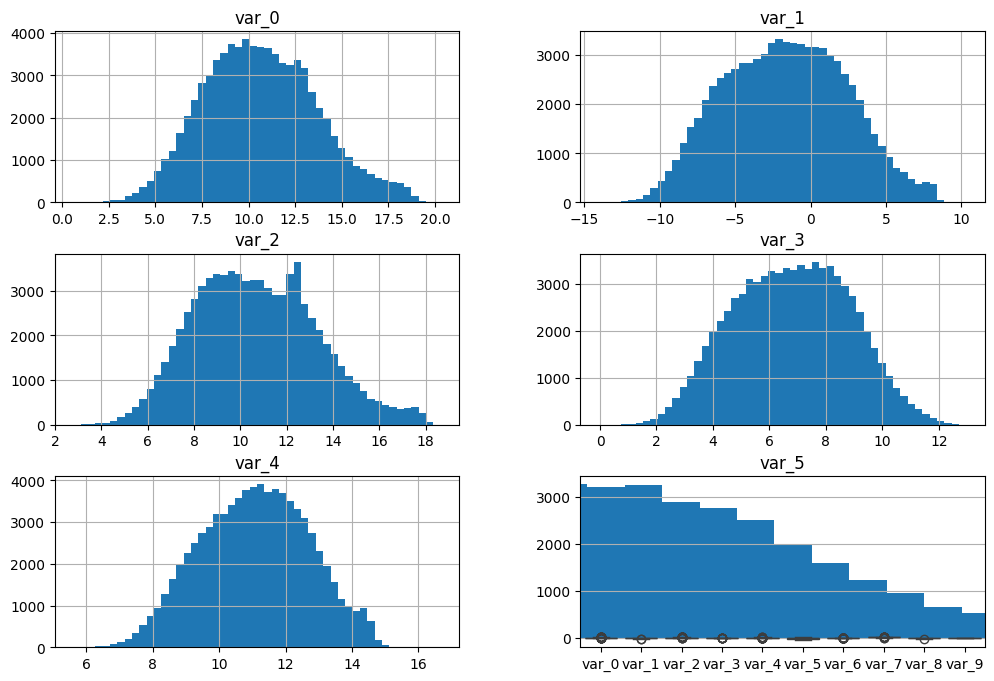

In [18]:
features = [c for c in df.columns if c.startswith('var_')]

df[features[:6]].hist(bins=50, figsize=(12,8))

skew = df[features].skew().sort_values()
print(skew.head(), skew.tail())

corr = df[features + ['target']].corr()['target'].drop('target').sort_values()
print(corr.head(10)); print(corr.tail(10))

sns.boxplot(data=df[features[:10]])

**Step 5: Preprocessing**

In [19]:
X = df[features]
y = df['target']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

In [21]:
from sklearn.impute import SimpleImputer

# Impute missing values with the mean
imputer = SimpleImputer(strategy='mean')

# Fit on training data and transform both sets
X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)

# Scale the imputed datasets
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_imp)
X_val_s = scaler.transform(X_val_imp)

**Step 6: Handle class imbalance**

Three options. Try them and compare:

1. Class weights (simplest): class_weight='balanced' or scale_pos_weight in LightGBM and XGBoost.
2. SMOTE (oversampling), applied only to training data:

In [22]:
sm = SMOTE(random_state=42)
X_tr_sm, y_tr_sm = sm.fit_resample(X_train_s, y_train)
print("Resampled dataset shape:", X_tr_sm.shape)

Resampled dataset shape: (111948, 200)


**Step 7: Baseline and multiple models (Model Comparison Report)**

In [23]:
results = {}

def evaluate(name, model, Xt, yt, Xv, yv):
    model.fit(Xt, yt)
    prob = model.predict_proba(Xv)[:,1]
    pred = (prob > 0.5).astype(int)
    results[name] = {
        'ROC-AUC': roc_auc_score(yv, prob),
        'F1': f1_score(yv, pred),
    }
    print(name, results[name])

evaluate("LogReg (balanced)", LogisticRegression(class_weight='balanced', max_iter=1000),
         X_train_s, y_train, X_val_s, y_val)

evaluate("LogReg + SMOTE", LogisticRegression(max_iter=1000),
         X_tr_sm, y_tr_sm, X_val_s, y_val)

evaluate("Random Forest", RandomForestClassifier(n_estimators=200, class_weight='balanced',
         n_jobs=-1, random_state=42), X_train, y_train, X_val, y_val)

evaluate("XGBoost", xgb.XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=3,
         scale_pos_weight=9, eval_metric='auc', n_jobs=-1), X_train, y_train, X_val, y_val)

evaluate("LightGBM", lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.02, num_leaves=8,
         scale_pos_weight=9, colsample_bytree=0.3, n_jobs=-1), X_train, y_train, X_val, y_val)

pd.DataFrame(results).T.sort_values('ROC-AUC', ascending=False)

LogReg (balanced) {'ROC-AUC': np.float64(0.859915949835564), 'F1': 0.41772586739951906}
LogReg + SMOTE {'ROC-AUC': np.float64(0.8572542391513454), 'F1': 0.4219245682058512}
Random Forest {'ROC-AUC': np.float64(0.8005980386768169), 'F1': 0.0}
XGBoost {'ROC-AUC': np.float64(0.8642140279037385), 'F1': 0.4586096256684492}
[LightGBM] [Info] Number of positive: 6242, number of negative: 55974
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.131837 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 51000
[LightGBM] [Info] Number of data points in the train set: 62216, number of used features: 200
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.100328 -> initscore=-2.193587
[LightGBM] [Info] Start training from score -2.193587
LightGBM {'ROC-AUC': np.float64(0.8751123111734043), 'F1': 0.46165976739601816}


,ROC-AUC,F1
LightGBM,0.875112,0.461660
XGBoost,0.864214,0.458610
LogReg (balanced),0.859916,0.417726
LogReg + SMOTE,0.857254,0.421925
Random Forest,0.800598,0.000000


**Step 8: Feature engineering (optional boost)**

The top solutions on this dataset used frequency/count encoding per feature (how many times each value appears), because the value counts carry hidden signal:

In [24]:
for f in features:
    df[f + '_count'] = df[f].map(df[f].value_counts())

/tmp/ipykernel_18678/1068715574.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f + '_count'] = df[f].map(df[f].value_counts())
/tmp/ipykernel_18678/1068715574.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f + '_count'] = df[f].map(df[f].value_counts())
/tmp/ipykernel_18678/1068715574.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a 

**Step 9: Hyperparameter tuning**

In [25]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'num_leaves': [4, 8, 16],
    'learning_rate': [0.01, 0.02, 0.05],
    'n_estimators': [500, 1000, 1500],
    'colsample_bytree': [0.2, 0.3, 0.5],
    'min_child_samples': [20, 50, 100],
}
search = RandomizedSearchCV(lgb.LGBMClassifier(scale_pos_weight=9, n_jobs=-1),
                            param_dist, n_iter=15, scoring='roc_auc',
                            cv=StratifiedKFold(5, shuffle=True, random_state=42))
search.fit(X_train, y_train)
print(search.best_params_, search.best_score_)

[LightGBM] [Info] Number of positive: 4993, number of negative: 44779
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.211352 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 51000
[LightGBM] [Info] Number of data points in the train set: 49772, number of used features: 200
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.100317 -> initscore=-2.193702
[LightGBM] [Info] Start training from score -2.193702
[LightGBM] [Info] Number of positive: 4994, number of negative: 44779
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.094628 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 51000
[LightGBM] [Info] Number of data points in the train set: 49773, number of used features: 200
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.100336 -> initscore=-2.193502
[LightGBM] [Info] Start training from score -2.193502
[LightGBM]

**Step 10: Final evaluation**

0.8882444279550389
              precision    recall  f1-score   support

           0       0.96      0.88      0.92     13995
           1       0.39      0.71      0.51      1560

    accuracy                           0.86     15555
   macro avg       0.68      0.79      0.71     15555
weighted avg       0.91      0.86      0.88     15555

Best threshold: 0.6419635751026714


<Axes: >

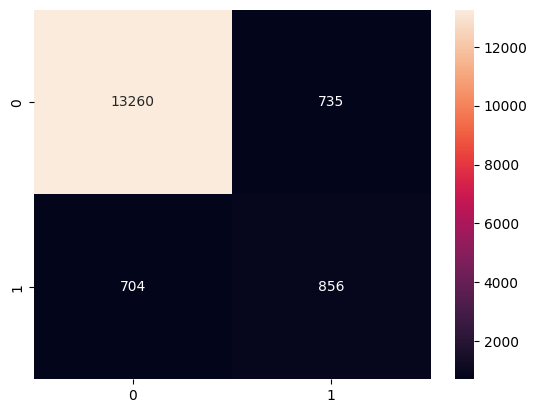

In [26]:
best = search.best_estimator_
prob = best.predict_proba(X_val)[:,1]

print(roc_auc_score(y_val, prob))
print(classification_report(y_val, (prob>0.5).astype(int)))

# Tune the threshold using the precision-recall curve
p, r, t = precision_recall_curve(y_val, prob)
f1s = 2*p*r/(p+r+1e-9)
best_t = t[np.argmax(f1s[:-1])]
print("Best threshold:", best_t)

sns.heatmap(confusion_matrix(y_val, (prob>best_t).astype(int)), annot=True, fmt='d')

**Plot the ROC curve and feature importance too:**

<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

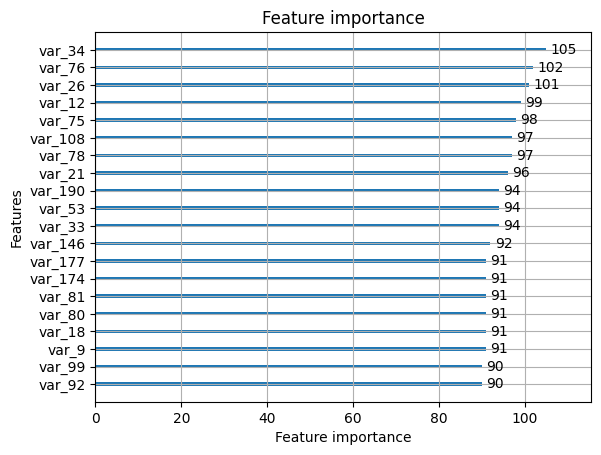

In [27]:
lgb.plot_importance(best, max_num_features=20)

**Step 11: Predict on test data**

In [31]:
# Create a simulated test.csv from our dataset if it doesn't exist
import os

if not os.path.exists("test.csv"):
    print("Creating a simulated test.csv from a slice of the main dataset for testing purposes...")
    simulated_test = df.sample(n=10000, random_state=42).copy()
    simulated_test = simulated_test.drop(columns=['target'], errors='ignore')
    simulated_test.to_csv("test.csv", index=False)

# Load and predict on test data
test_data = pd.read_csv("test.csv")

# Handle imputation for test features if any NaNs exist
test_features = test_data[features]
test_features_imp = imputer.transform(test_features)

# Generate predictions using our best estimator
test_pred = best.predict_proba(test_features_imp)[:, 1]

# Save the final submission
submission = pd.DataFrame({
    'ID_code': test_data['ID_code'],
    'target': test_pred
})
submission.to_csv("submission.csv", index=False)

print("Predictions successfully saved to submission.csv!")
display(submission.head())

Creating a simulated test.csv from a slice of the main dataset for testing purposes...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Predictions successfully saved to submission.csv!


,ID_code,target
0,train_59065,0.556562
1,train_48906,0.499052
2,train_8388,0.159391
3,train_71901,0.059583
4,train_76604,0.434836
